# Предсказание значений диоксида азота (NO2) с помощью машинного обучения (регрессия)
Используемые модели:
1. RandomForestRegressor
2. ElasticNet
3. HistGradientBoostingRegressor
4. ExtraTreesRegressor
5. XGBoost
6. LightGBM

### Загрузка и объединение данных

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# --- Определяем целевую переменную ---
TARGET = 'Диоксид азота'

# --- Загрузка и объединение данных ---
filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

all_dfs = []

for name in filenames:
    try:
        file_path = name + ".csv"
        df_station = pd.read_csv(file_path, encoding="cp1251", sep=";")
        all_dfs.append(df_station)
    except FileNotFoundError:
        print(f"Файл {file_path} не найден, пропускаем.")
        continue

full_df = pd.concat(all_dfs, ignore_index=True)

# --- Обработка столбца Время ---
full_df['Время'] = pd.to_datetime(full_df['Время'], dayfirst=True, errors='coerce')
full_df.dropna(subset=['Время'], inplace=True) # Удаляем строки, где дата не распозналась
full_df.set_index('Время', inplace=True)
full_df.sort_index(inplace=True) # Сортируем по времени

# --- Создание признаков (Feature Engineering) ---
df = full_df.copy()

# 1. Временные признаки
df['час'] = df.index.hour
df['день_недели'] = df.index.dayofweek # 0 = Понедельник, 6 = Воскресенье
df['месяц'] = df.index.month

# 2. Лаговые признаки
# Предсказываем значение, основываясь на том, каким оно было в прошлом
lags = [1, 2, 3, 6, 24] # Лаги на 1, 2, 3, 6 и 24 часа назад
for lag in lags:
    df[f'{TARGET}_lag_{lag}h'] = df[TARGET].shift(lag)

### 1. RandomForestRegressor


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели RandomForestRegressor ---

Качество модели на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0132
Среднеквадратичная ошибка (RMSE): 0.0222
Коэффициент детерминации (R²): 0.3470


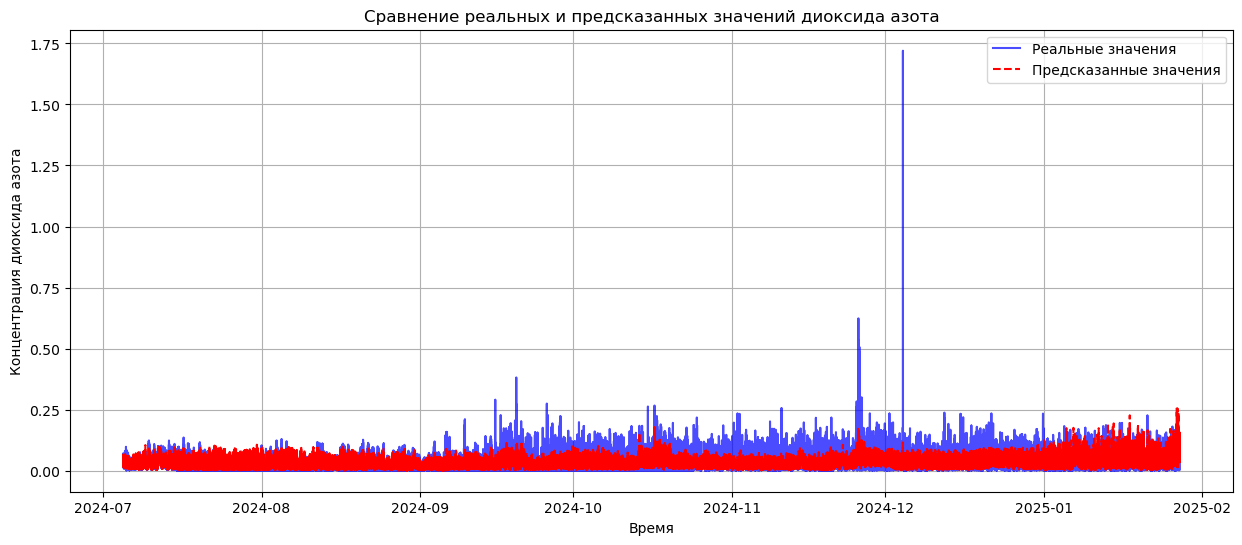


Топ-15 самых важных признаков для модели
Оксид азота              0.333218
Оксид углерода           0.203561
месяц                    0.074944
Номер                    0.065549
Диоксид азота_lag_6h     0.055640
Аммиак                   0.036617
Температура              0.032743
Диоксид азота_lag_3h     0.027280
Диоксид азота_lag_2h     0.023597
час                      0.022332
Диоксид серы             0.022289
Влажность отн.           0.019622
Диоксид азота_lag_24h    0.018256
Диоксид азота_lag_1h     0.017891
Скорость ветра           0.013642
dtype: float64


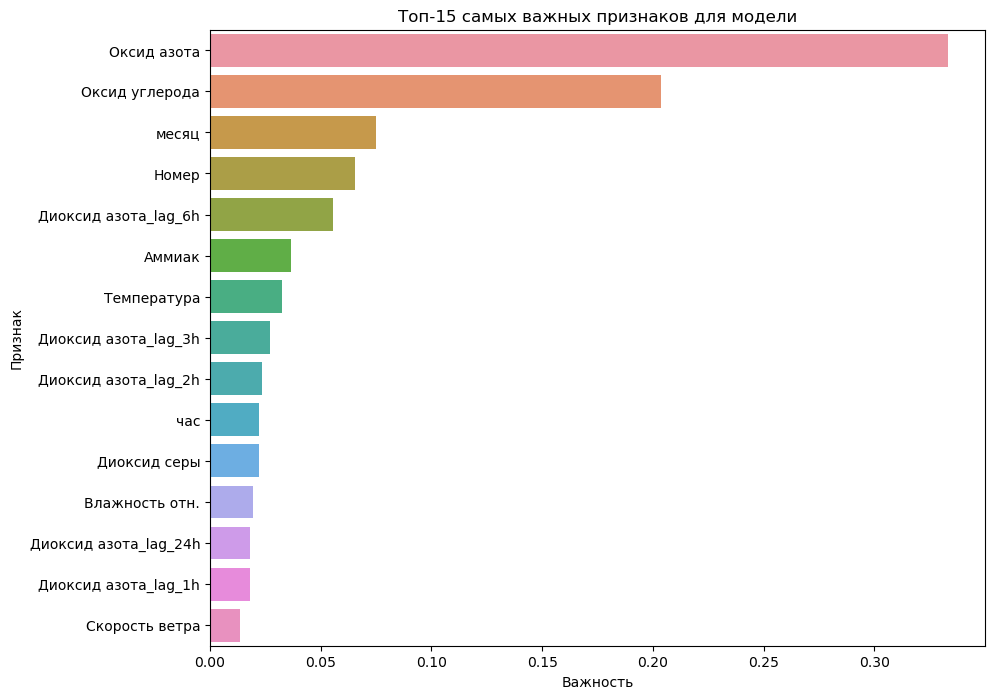

In [8]:
from sklearn.ensemble import RandomForestRegressor

# --- Финальная подготовка к обучению ---
# Копируем датафрейм, чтобы не изменять оригинал
df_model = df.copy()

# Удаляем столбцы, в которых слишком много пропусков (например, > 50%)
min_valid_values = len(df_model) * 0.5  # Минимальное кол-во не-пропущенных значений (50%)
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

# Заполняем оставшиеся пропуски медианой (для числовых признаков)
# Это безопаснее, чем удалять строки целиком
numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

# Теперь, когда большинство пропусков обработано, удаляем строки,
# где лаговые признаки остались пустыми (это только первые несколько строк)
df_model.dropna(inplace=True)

# Определяем признаки (X) и цель (y)
if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---

# Разделение данных до применения кодирования, чтобы избежать утечки данных
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("\n--- Обучение модели RandomForestRegressor ---")
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, min_samples_leaf=5)
model.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---

predictions = model.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# Важность признаков извлекается сложнее, так как теперь есть One-Hot закодированные признаки.
# Нужно получить имена признаков после преобразования.
feature_importances = pd.Series(model.feature_importances_, index=X_train_raw.columns).sort_values(ascending=False)

# --- Численный вывод топ-15 признаков ---
print("\nТоп-15 самых важных признаков для модели")
print(feature_importances.head(15))

# --- Графический вывод топ-15 признаков ---
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
plt.title('Топ-15 самых важных признаков для модели')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()

### 2. ElasticNet


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели ElasticNet ---

Качество модели ElasticNet на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0169
Среднеквадратичная ошибка (RMSE): 0.0245
Коэффициент детерминации (R²): 0.2050


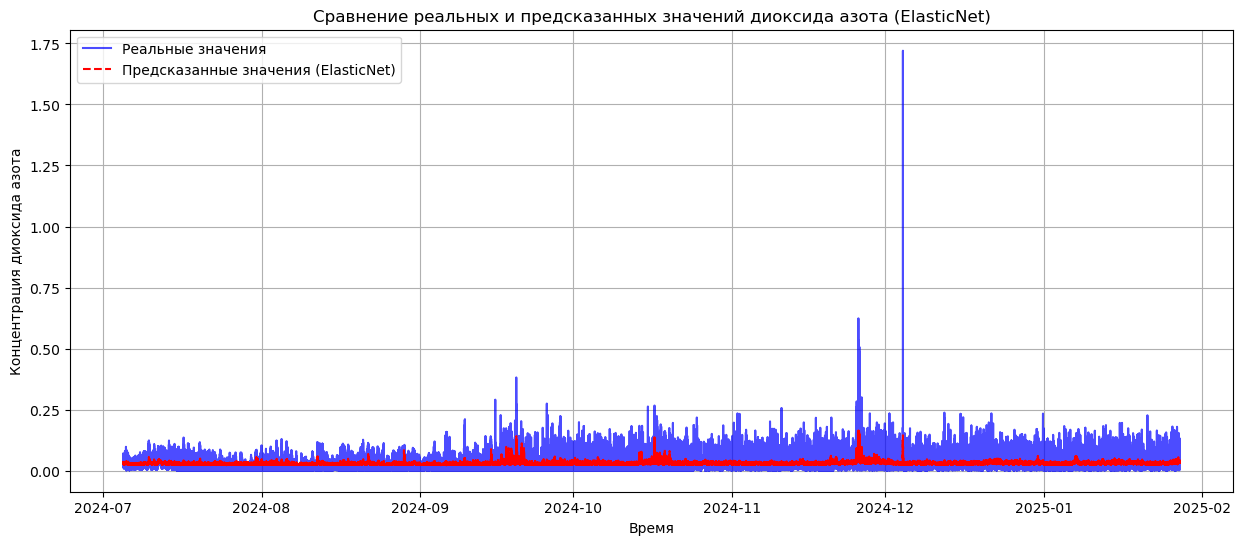


Топ-15 самых важных признаков для модели
Оксид азота              0.002760
Диоксид азота_lag_6h     0.001581
Диоксид азота_lag_24h    0.000970
Диоксид азота_lag_3h     0.000847
Диоксид азота_lag_2h     0.000828
Диоксид азота_lag_1h     0.000183
Номер_26                 0.000000
Номер_9                 -0.000000
Номер_7                 -0.000000
Номер_6                 -0.000000
Номер_5                 -0.000000
Номер_4                  0.000000
Номер_3                  0.000000
Номер_2                  0.000000
Номер_1                 -0.000000
dtype: float64


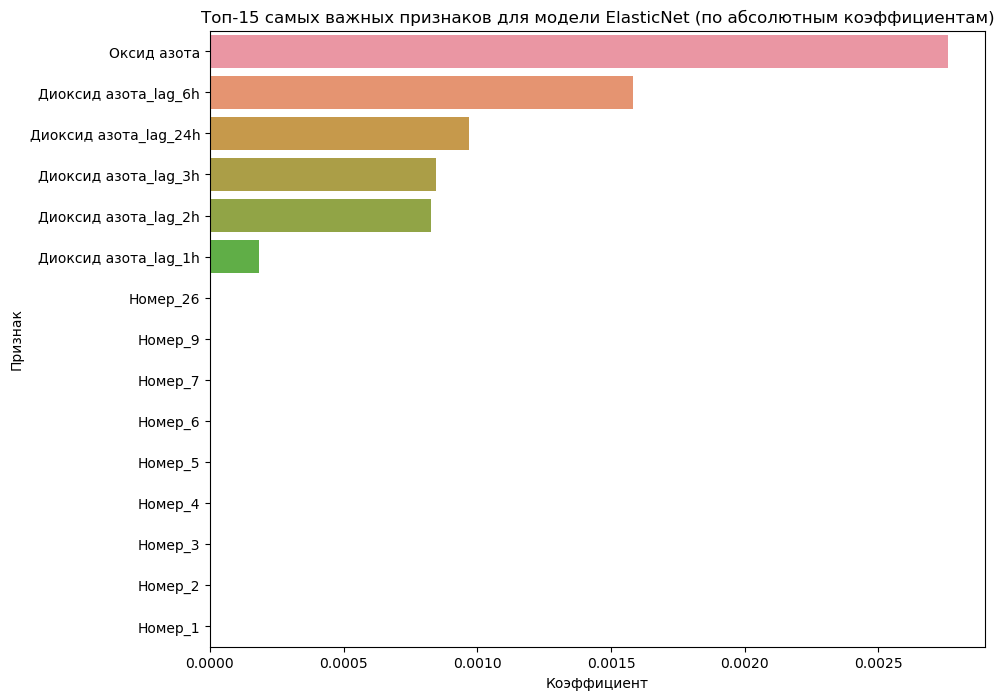

In [16]:
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# --- Финальная подготовка к обучению ---
df_model = df.copy()
min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

df_model.dropna(inplace=True)

if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

numerical_features = X_train_raw.select_dtypes(include=np.number).columns
categorical_features = ['Номер']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

print("\n--- Обучение модели ElasticNet ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # Уменьшаем alpha, чтобы ослабить регуляризацию, и увеличиваем l1_ratio для большего отбора признаков
    ('regressor', ElasticNet(alpha=0.01, l1_ratio=0.7, random_state=42, max_iter=10000))
])

model_pipeline.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---
predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели ElasticNet на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения (ElasticNet)', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота (ElasticNet)')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# Важность признаков для ElasticNet
coefficients = model_pipeline.named_steps['regressor'].coef_

# Получаем имена признаков после всех преобразований
ohe_feature_names = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Номер'])
numerical_features_list = list(numerical_features)
processed_feature_names = numerical_features_list + list(ohe_feature_names) + list(X_train_raw.columns.difference(numerical_features).difference(categorical_features))

# Проверяем, что количество коэффициентов совпадает с количеством признаков
if len(coefficients) != len(processed_feature_names):
    # Если не совпадает, значит, что-то пошло не так в логике определения признаков.
    # Это может быть из-за `remainder='passthrough'`, который может дублировать признаки.
    # Логика ниже исправляет это.
    all_cols = numerical_features_list + ['Номер'] + [col for col in X_train_raw.columns if col not in numerical_features_list + ['Номер']]
    ohe_feature_names_fixed = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Номер'])
    
    # Теперь собираем имена признаков в правильном порядке
    final_features_list = []
    final_features_list.extend(numerical_features_list)
    final_features_list.extend(ohe_feature_names_fixed)
    
    # Добавляем оставшиеся, если есть
    passthrough_cols = X_train_raw.columns.drop(numerical_features_list + ['Номер'])
    final_features_list.extend(passthrough_cols)

    feature_importances_enet = pd.Series(coefficients, index=final_features_list).sort_values(key=abs, ascending=False)
    
else:
    feature_importances_enet = pd.Series(coefficients, index=processed_feature_names).sort_values(key=abs, ascending=False)

# --- Численный вывод топ-15 признаков ---
print("\nТоп-15 самых важных признаков для модели")
print(feature_importances_enet.head(15))

# --- Графический вывод топ-15 признаков ---
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances_enet.head(15), y=feature_importances_enet.head(15).index)
plt.title('Топ-15 самых важных признаков для модели ElasticNet (по абсолютным коэффициентам)')
plt.xlabel('Коэффициент')
plt.ylabel('Признак')
plt.show()

### 3. HistGradientBoostingRegressor


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели HistGradientBoostingRegressor ---

Качество модели HistGradientBoostingRegressor на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0075
Среднеквадратичная ошибка (RMSE): 0.0164
Коэффициент детерминации (R²): 0.6444


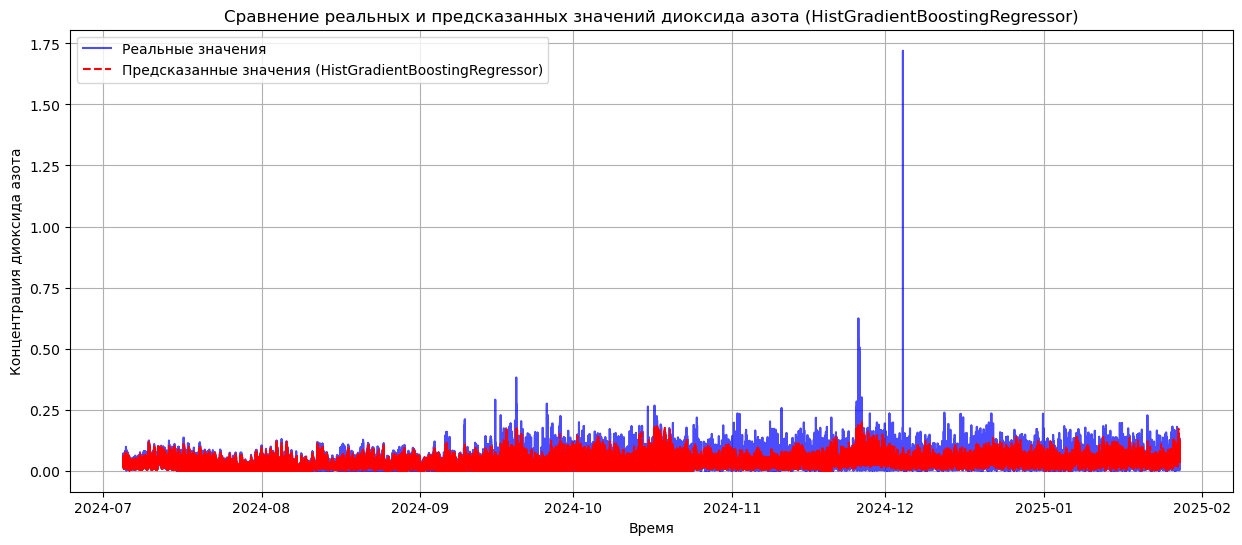


--- Оценка важности признаков с помощью Permutation Importance ---

Топ-15 самых важных признаков (Permutation Importance):
Диоксид азота_lag_1h     8.877157e-03
Диоксид азота_lag_3h     3.371868e-03
Диоксид азота_lag_2h     2.926607e-03
Оксид азота              6.890324e-04
Оксид углерода           4.122820e-04
Номер                    2.824581e-04
час                      1.090340e-04
Температура              1.055200e-04
Диоксид азота_lag_24h    9.592919e-05
Диоксид азота_lag_6h     5.806939e-05
Направление ветра        2.087485e-05
Влажность отн.           1.038951e-05
Диоксид серы             5.087447e-06
день_недели              9.713950e-07
месяц                   -1.457049e-05
dtype: float64


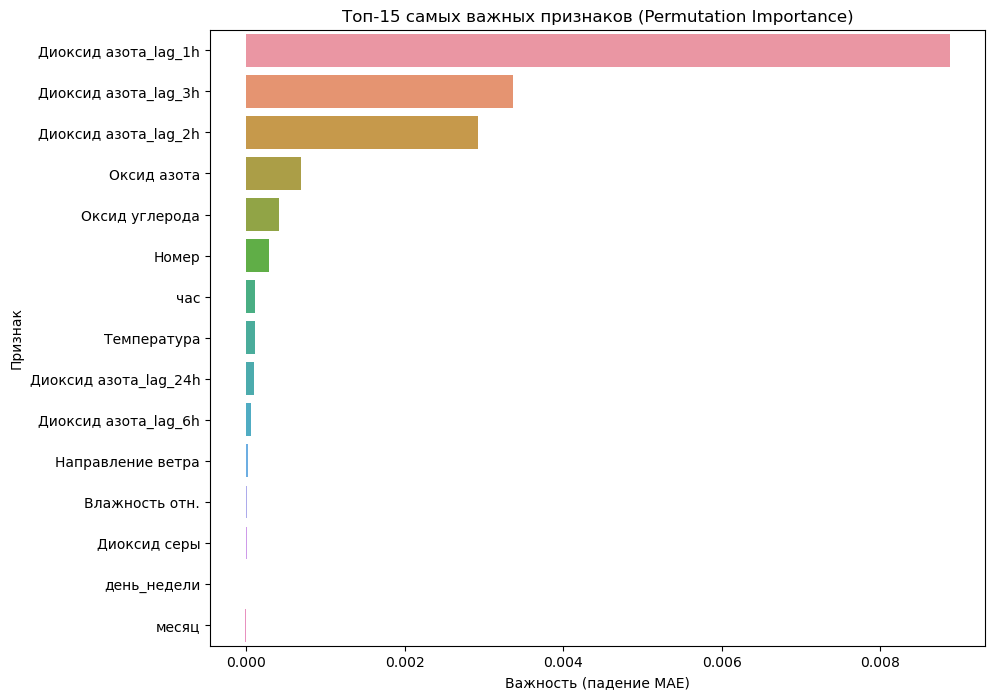

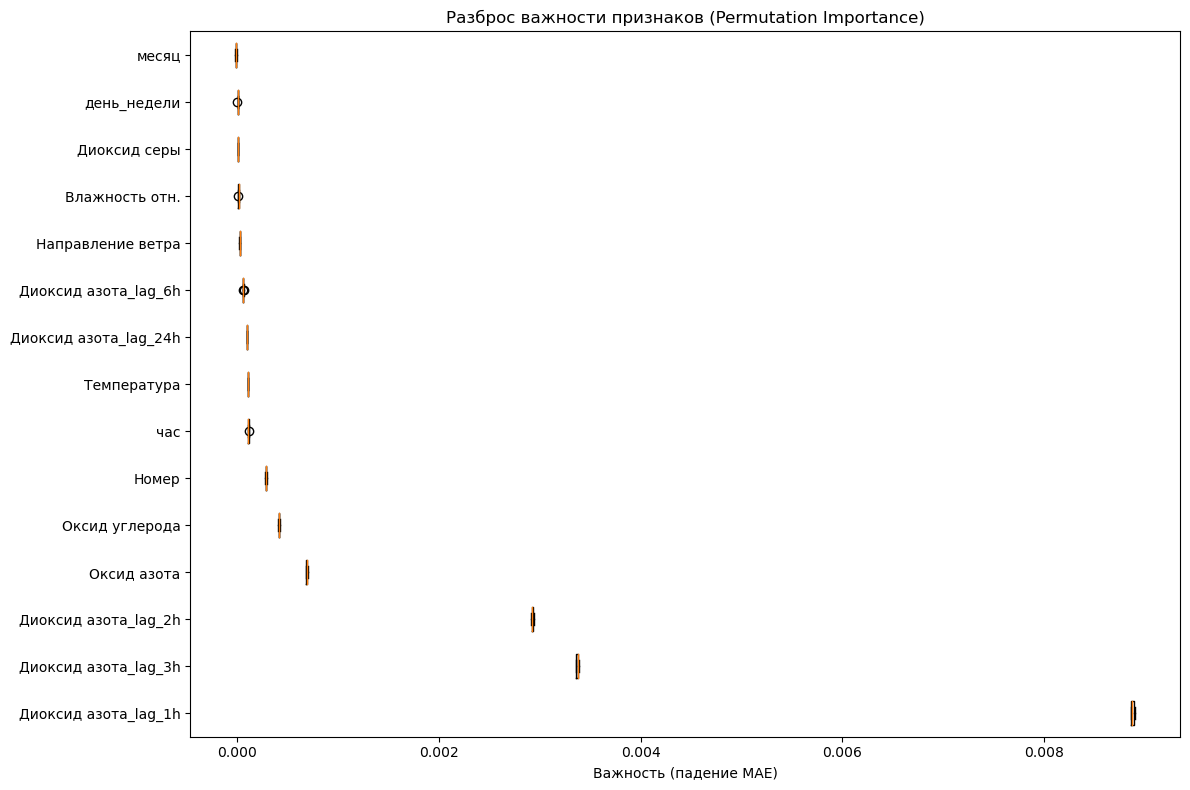

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance

# --- Финальная подготовка к обучению ---
df_model = df.copy()

min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

df_model.dropna(inplace=True)

if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

categorical_features = ['Номер']
numerical_features_remaining = [col for col in X_train_raw.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

print("\n--- Обучение модели HistGradientBoostingRegressor ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(random_state=42))
])

model_pipeline.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---
predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели HistGradientBoostingRegressor на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения (HistGradientBoostingRegressor)', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота (HistGradientBoostingRegressor)')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# --- Оценка важности признаков с помощью Permutation Importance ---
print("\n--- Оценка важности признаков с помощью Permutation Importance ---")

perm_importance = permutation_importance(
    model_pipeline,
    X_test_raw,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

original_feature_names = X_test_raw.columns.tolist()
feature_importances_pi = pd.Series(perm_importance.importances_mean, index=original_feature_names)
feature_importances_pi_sorted = feature_importances_pi.sort_values(ascending=False)

print("\nТоп-15 самых важных признаков (Permutation Importance):")
print(feature_importances_pi_sorted.head(15))

plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances_pi_sorted.head(15), y=feature_importances_pi_sorted.head(15).index)
plt.title('Топ-15 самых важных признаков (Permutation Importance)')
plt.xlabel('Важность (падение MAE)')
plt.ylabel('Признак')
plt.show()

plt.figure(figsize=(12, 8))
sorted_idx_for_plot = feature_importances_pi_sorted.head(15).index
name_to_index_map = {name: i for i, name in enumerate(original_feature_names)}
numerical_indices_for_plot = [name_to_index_map[name] for name in sorted_idx_for_plot]

plt.boxplot(perm_importance.importances[numerical_indices_for_plot].T,
            vert=False, labels=np.array(original_feature_names)[numerical_indices_for_plot])
plt.title("Разброс важности признаков (Permutation Importance)")
plt.xlabel("Важность (падение MAE)")
plt.tight_layout()
plt.show()

### 4. ExtraTreesRegressor


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели ExtraTreesRegressor ---

Качество модели ExtraTreesRegressor на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0070
Среднеквадратичная ошибка (RMSE): 0.0153
Коэффициент детерминации (R²): 0.6914


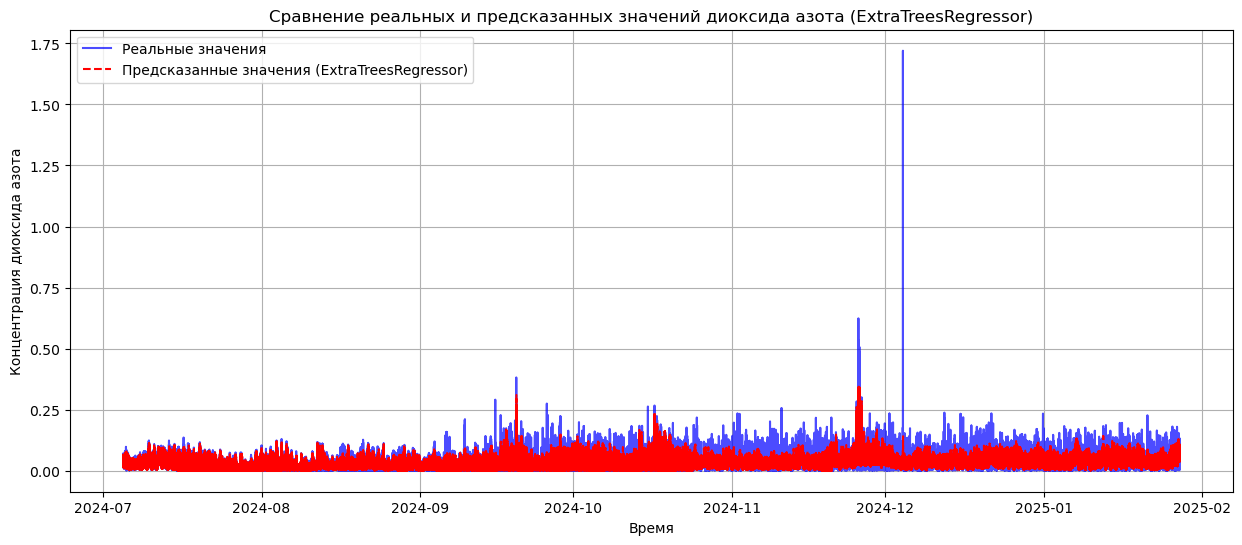


Топ-15 самых важных признаков для модели ExtraTreesRegressor:
Диоксид азота_lag_2h     0.307513
Диоксид азота_lag_1h     0.292503
Диоксид азота_lag_3h     0.170848
Диоксид азота_lag_6h     0.098101
Оксид азота              0.022026
Номер_5                  0.019792
Диоксид азота_lag_24h    0.017898
Оксид углерода           0.016355
Аммиак                   0.016316
Скорость ветра           0.007449
месяц                    0.005951
Температура              0.004060
час                      0.003333
Сероводород              0.003169
Влажность отн.           0.003095
dtype: float64


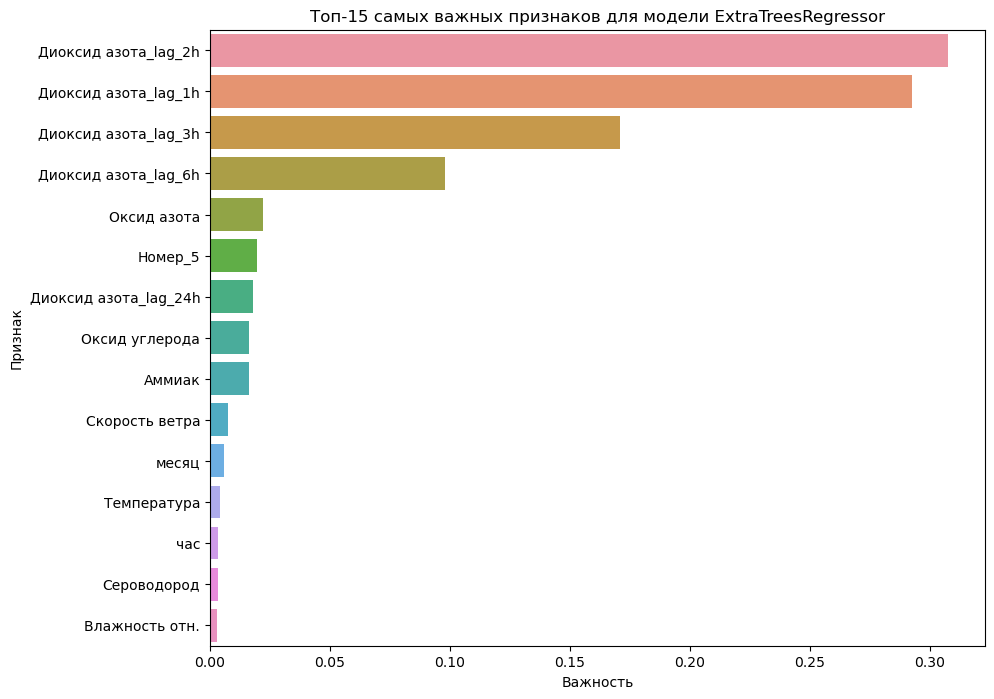

In [11]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- Финальная подготовка к обучению ---
df_model = df.copy()

min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

df_model.dropna(inplace=True)

if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---

train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

categorical_features = ['Номер']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

print("\n--- Обучение модели ExtraTreesRegressor ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1, min_samples_leaf=5))
])

model_pipeline.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---

predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели ExtraTreesRegressor на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения (ExtraTreesRegressor)', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота (ExtraTreesRegressor)')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# --- Важность признаков для ExtraTreesRegressor ---
ohe_feature_names = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Номер'])
passthrough_features = [col for col in X_train_raw.columns if col not in categorical_features]

all_feature_names = list(ohe_feature_names) + list(passthrough_features)

feature_importances = pd.Series(model_pipeline.named_steps['regressor'].feature_importances_, index=all_feature_names).sort_values(ascending=False)

# --- Численный вывод топ-15 признаков ---
print("\nТоп-15 самых важных признаков для модели ExtraTreesRegressor:")
print(feature_importances.head(15))

# --- Графический вывод топ-15 признаков ---
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
plt.title('Топ-15 самых важных признаков для модели ExtraTreesRegressor')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()

### 5. XGBoost

In [12]:
# pip install xgboost


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели XGBoostRegressor ---

Качество модели на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0128
Среднеквадратичная ошибка (RMSE): 0.0213
Коэффициент детерминации (R²): 0.4010


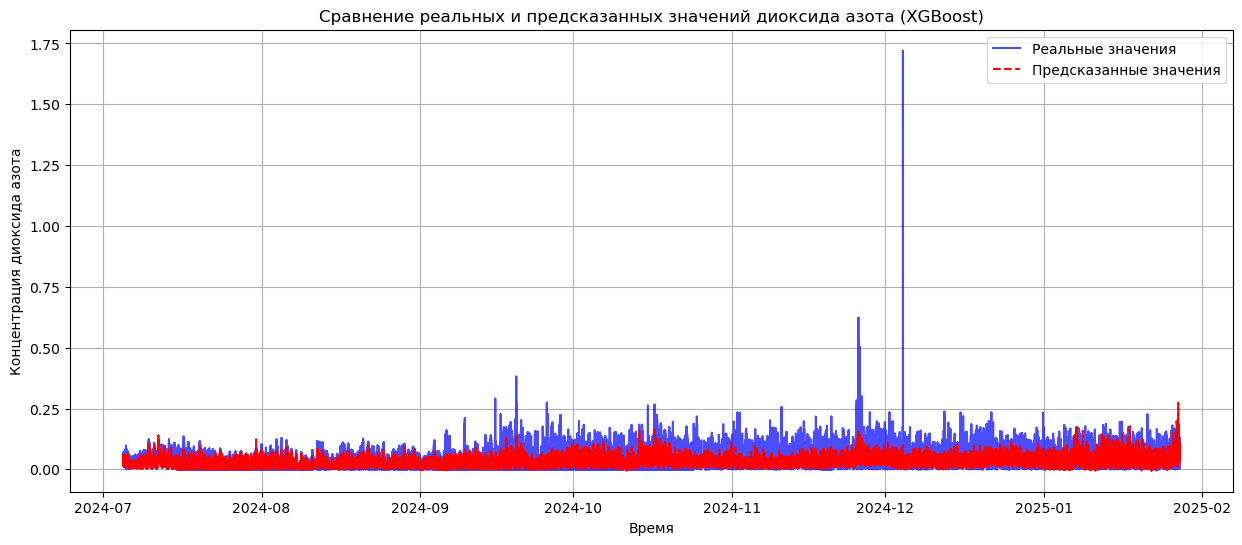


Топ-15 самых важных признаков для модели
Оксид азота              0.114865
Оксид углерода           0.102210
Диоксид азота_lag_6h     0.090650
Диоксид азота_lag_3h     0.075159
Диоксид азота_lag_24h    0.074064
Диоксид азота_lag_2h     0.063753
Номер_2                  0.050319
Номер_4                  0.044865
Диоксид азота_lag_1h     0.043284
Номер_3                  0.042127
Номер_26                 0.034367
месяц                    0.032919
Аммиак                   0.027949
Номер_6                  0.026118
Номер_5                  0.023742
dtype: float32


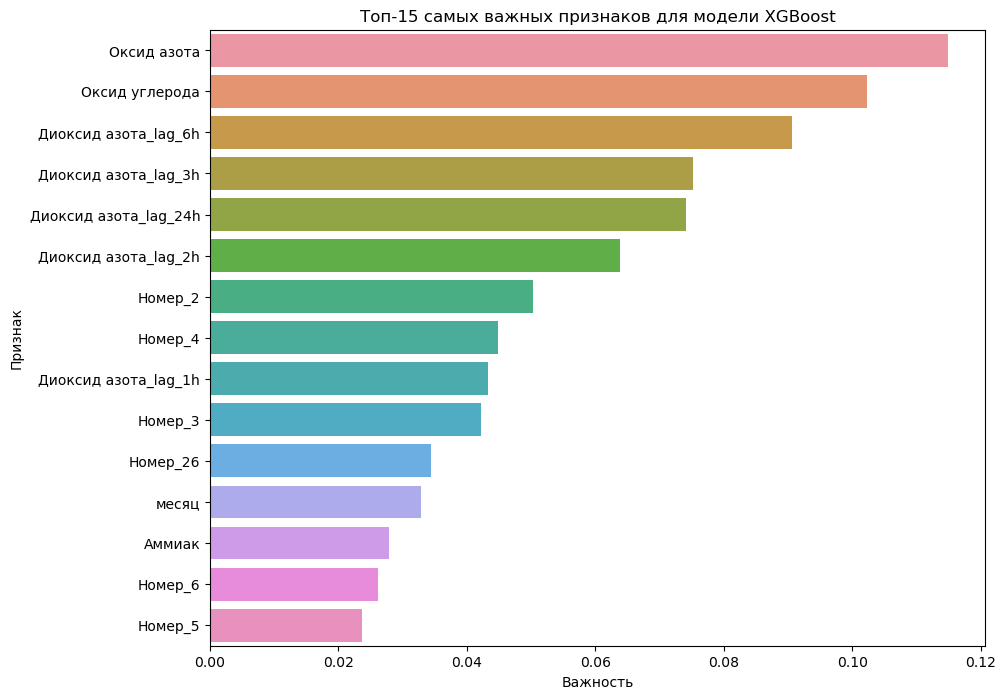

In [21]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

# --- Финальная подготовка к обучению ---
df_model = df.copy()

min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

df_model.dropna(inplace=True)

if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Номер'])
    ],
    remainder='passthrough'
)

print("\n--- Обучение модели XGBoostRegressor ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=500,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        tree_method='hist',
    ))
])

model_pipeline.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---
predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота (XGBoost)')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# Важность признаков
ohe_feature_names = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Номер'])
passthrough_features = [col for col in X_train_raw.columns if col != 'Номер']
all_feature_names = list(ohe_feature_names) + list(passthrough_features)

feature_importances = pd.Series(model_pipeline.named_steps['regressor'].feature_importances_, index=all_feature_names).sort_values(ascending=False)

# --- Численный вывод топ-15 признаков ---
print("\nТоп-15 самых важных признаков для модели")
print(feature_importances.head(15))

# --- Графический вывод топ-15 признаков ---
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
plt.title('Топ-15 самых важных признаков для модели XGBoost')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()

### 6. LightGBM

In [19]:
# pip install lightgbm


Столбцы, оставленные после удаления пропусков: ['Номер', 'Диоксид серы', 'Оксид углерода', 'Диоксид азота', 'Оксид азота', 'Сероводород', 'Аммиак', 'Температура', 'Влажность отн.', 'Направление ветра', 'Скорость ветра', 'час', 'день_недели', 'месяц', 'Диоксид азота_lag_1h', 'Диоксид азота_lag_2h', 'Диоксид азота_lag_3h', 'Диоксид азота_lag_6h', 'Диоксид азота_lag_24h']

Размер итоговой выборки: 744041 строк, 18 признаков.

--- Обучение модели LGBMRegressor ---
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017485 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3120
[LightGBM] [Info] Number of data points in the train set: 595232, number of used features: 27
[LightGBM] [Info] Start training from score 0.029413

Качество модели на тестовых данных:
Средняя абсолютная ошибка (MAE): 0.0127
Среднеквадратичная ошибка (RMSE): 0.0211
Коэффицие

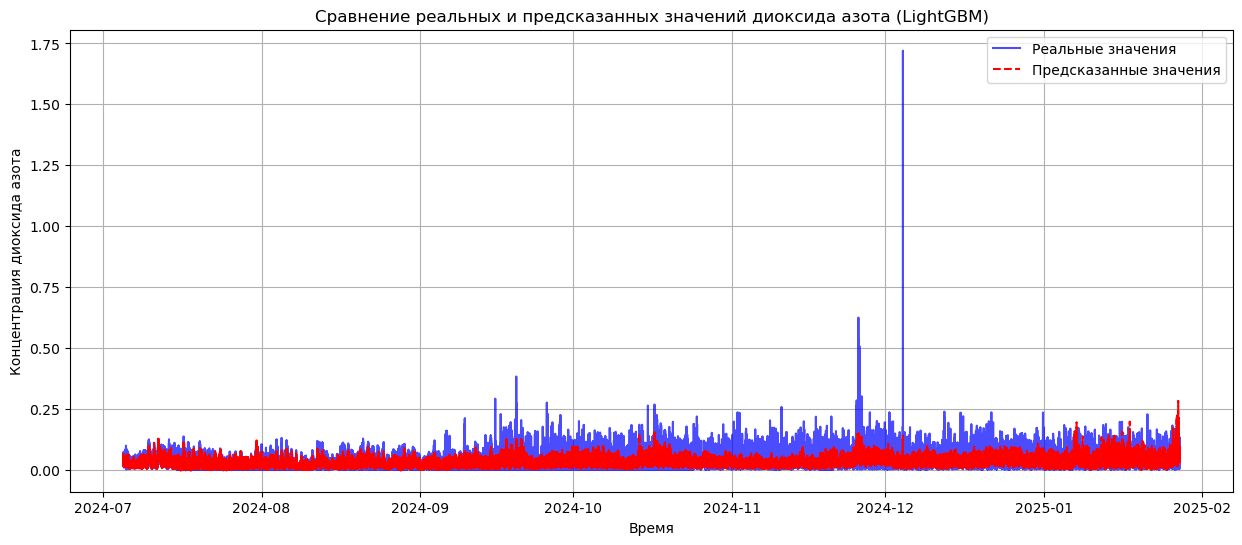


Топ-15 самых важных признаков для модели LightGBM:
Оксид азота          2209
месяц                1965
Оксид углерода       1431
Аммиак               1158
Температура          1053
Диоксид серы          742
час                   701
Направление ветра     646
Влажность отн.        565
Сероводород           424
Номер_3               409
Номер_2               402
Скорость ветра        358
Номер_5               345
Номер_4               301
dtype: int32


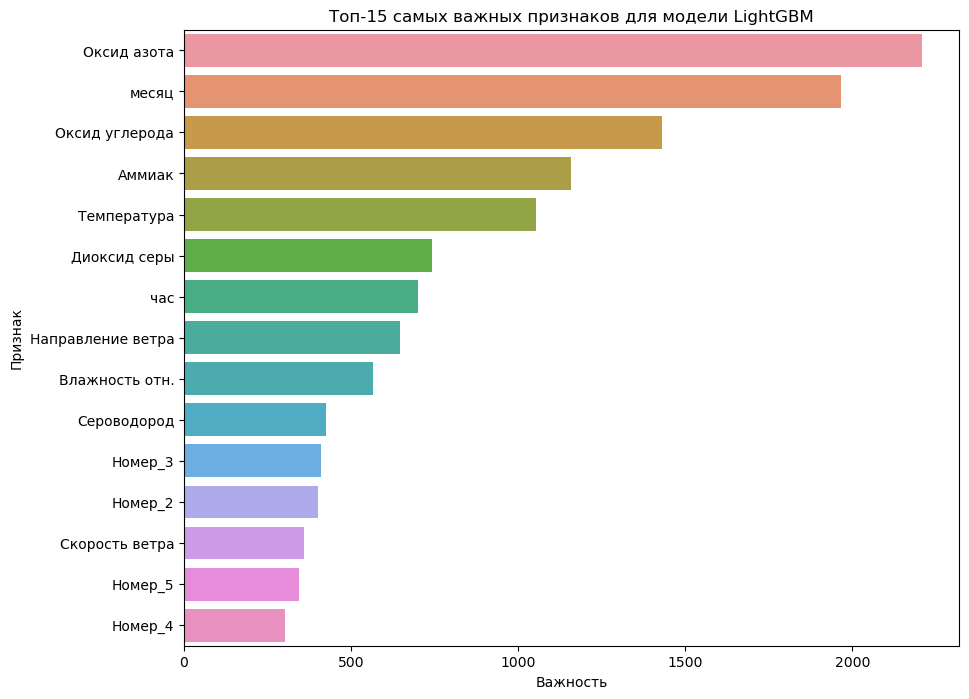

In [22]:
import lightgbm as lgb

# --- Финальная подготовка к обучению ---
df_model = df.copy()

min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
print(f"\nСтолбцы, оставленные после удаления пропусков: {df_model.columns.tolist()}")

numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    median_val = df_model[col].median()
    df_model[col].fillna(median_val, inplace=True)

df_model.dropna(inplace=True)

# Определяем признаки (X) и цель (y)
if TARGET not in df_model.columns:
    raise ValueError(f"Целевая переменная '{TARGET}' отсутствует в данных после очистки!")

y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")
if X.shape[0] == 0:
    raise SystemExit("ОШИБКА: После очистки данных не осталось ни одной строки. Проверьте ваш исходный CSV файл на наличие данных.")

# --- Разделение данных и обучение модели ---
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Номер'])
    ],
    remainder='passthrough'
)

print("\n--- Обучение модели LGBMRegressor ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', lgb.LGBMRegressor(
        objective='regression',
        n_estimators=500,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
    ))
])

model_pipeline.fit(X_train_raw, y_train)

# --- Оценка и демонстрация ---
predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f"\nКачество модели на тестовых данных:")
print(f"Средняя абсолютная ошибка (MAE): {mae:.4f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.4f}")
print(f"Коэффициент детерминации (R²): {r2:.4f}")

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Реальные значения', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказанные значения', color='red', linestyle='--')
plt.title('Сравнение реальных и предсказанных значений диоксида азота (LightGBM)')
plt.xlabel('Время')
plt.ylabel('Концентрация диоксида азота')
plt.legend()
plt.grid(True)
plt.show()

# Важность признаков
ohe_feature_names = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Номер'])
passthrough_features = [col for col in X_train_raw.columns if col != 'Номер']
all_feature_names = list(ohe_feature_names) + list(passthrough_features)

feature_importances = pd.Series(model_pipeline.named_steps['regressor'].feature_importances_, index=all_feature_names).sort_values(ascending=False)

# --- Численный вывод топ-15 признаков ---
print("\nТоп-15 самых важных признаков для модели LightGBM:")
print(feature_importances.head(15))

# --- Графический вывод топ-15 признаков ---
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances.head(15), y=feature_importances.head(15).index)
plt.title('Топ-15 самых важных признаков для модели LightGBM')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()